# G4 - The gamma source and $T(r)$

**057922 Nuclear Design and Technology** · Project Lab

> Before starting: the gamma source of your wall at the wetted surface, at the vessel inner surface and at the vessel outer surface.

Author: Giovanni Zullo

---

## In this notebook

Where the heat in the wall comes from, how it is distributed through
the thickness, and the temperature field it produces. Then the two questions the assignment
asks of that field: **where is the maximum, and how much is it?**, and **what is the average
through the thickness?**, because the average is your **design temperature**, and with it the
thickness you started from stops being tentative. First on a neutral wall, then on your
vessel, with $h_1$ and $U_2$ from G3, ending with your own design conditions closed.

## The thing to understand

A wall heated *from inside itself* behaves nothing like a wall heated *through a face*.
With a surface heat flux the temperature profile is monotonic and the extremes are at the
faces: you read the maximum off a boundary. With a **volumetric** source the peak is
somewhere in the middle, and finding it is part of the answer.

That single difference is what makes the vessel problem interesting, and it is why the
peak thermal stress sits where it does.

Tutoring module M4 is the reference for the conduction solutions.

---
## Step 0: Environment

In [1]:
# --- where is the course material? (Colab only; a no-op on your own machine) -------
# Nothing to configure. Three places are tried, in the order that costs least:
#   1. already on disk next to this notebook  -> nothing to do
#   2. fetchable from GitHub                  -> the next cell downloads it
#   3. neither                                -> mount Google Drive and look there
# Drive is the LAST resort on purpose: when the course repository is public, step 2
# succeeds and nobody is ever asked to authorise Drive. When it is not -- a private
# repo, or no network -- step 3 is exactly what is needed, so it happens by itself.
import os, glob, urllib.request

URL = ('https://raw.githubusercontent.com/giozu/ndt-labs/'
       'main/launcher/ndt_setup.py')

def _on_colab():
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False

def _find_labs(start=None):
    # The course folder above us, or None. Same walk-up the bootstrap uses.
    d = os.path.abspath(start or os.getcwd())
    while True:
        if os.path.isfile(os.path.join(d, 'launcher', 'ndt_setup.py')):
            return d
        parent = os.path.dirname(d)
        if parent == d:
            return None
        d = parent

def _github_has_it():
    try:
        req = urllib.request.Request(URL, method='HEAD')
        with urllib.request.urlopen(req, timeout=8) as r:
            return r.status == 200
    except Exception:
        return False

def _search_drive():
    # The obvious place first -- the course folder uploaded to the top of My Drive --
    # then one or two folders down, in case it was tidied away. NOT a deep recursive
    # hunt: if it is not within reach of these, the problem is not the depth.
    D = '/content/drive/MyDrive'
    for pat in (f'{D}/ndt-labs/launcher/ndt_setup.py',
                f'{D}/*/launcher/ndt_setup.py',
                f'{D}/*/*/launcher/ndt_setup.py'):
        hits = glob.glob(pat)
        if hits:
            return hits[0]
    return None


if not _on_colab():
    print('[where] local machine - the files are already here')
elif _find_labs():
    print('[where] already here:', _find_labs())
elif _github_has_it():
    print('[where] will be downloaded from GitHub by the next cell')
else:
    print('[where] not on disk and not reachable on GitHub - looking on Google Drive')
    from google.colab import drive
    drive.mount('/content/drive')

    # A mount can succeed and still show NOTHING: a stale mount left by an earlier
    # attempt, or the wrong Google account. That looked exactly like "the folder is
    # somewhere unexpected" once, and sent the search deeper and deeper for nothing.
    # Distinguish the two, because the remedies have nothing in common.
    top = glob.glob('/content/drive/MyDrive/*')
    if not top:
        raise SystemExit(
            'Google Drive is mounted but MyDrive looks EMPTY.\n'
            'That is a mount problem, not a missing folder. Either an earlier mount is\n'
            'stale, or you authorised a different Google account. Fix it with:\n'
            "    drive.mount('/content/drive', force_remount=True)\n"
            'and pick the account that holds the course folder. If it stays empty,\n'
            'Runtime -> Disconnect and delete runtime, then start again.')

    hit = _search_drive()
    if not hit:
        raise SystemExit(
            'Your Drive is readable but no launcher/ndt_setup.py was found in it.\n'
            'Top level of MyDrive:\n  ' + '\n  '.join(sorted(top)[:20]) + '\n'
            'Upload the course folder there, or os.chdir() into it by hand.')

    # The repository ROOT is enough: everything downstream walks up from the working
    # directory, so there is no per-notebook path to keep in sync here.
    os.chdir(os.path.dirname(os.path.dirname(hit)))
    print('[where] found on Drive:', os.getcwd())

print('cwd      :', os.getcwd())

[where] local machine - the files are already here
cwd      : ~/ndt-labs/sessions/G04_gamma_temperature


In [2]:
import os, sys, subprocess

# Get the shared bootstrap, ndt_setup.py. Two ways, and the notebook picks one:
#  - LOCAL: you cloned ndt-labs, so launcher/ndt_setup.py is already on disk a few
#    directories up. Use that copy -- no network, and any pin you edit takes effect.
#  - COLAB: fetch it. Check the file is NON-EMPTY: wget -O creates
#    a zero-byte file when the download fails, that file "exists", the download is then
#    skipped forever, and `import ndt_setup` silently imports nothing.
URL = ('https://raw.githubusercontent.com/giozu/ndt-labs/'
       'main/launcher/ndt_setup.py')

def _find_launcher(d=None):
    d = os.path.abspath(d or os.getcwd())
    while True:
        p = os.path.join(d, 'launcher', 'ndt_setup.py')
        if os.path.isfile(p) and os.path.getsize(p) > 0:
            return os.path.dirname(p)
        parent = os.path.dirname(d)
        if parent == d:
            return None
        d = parent

launcher = _find_launcher()
if launcher is None:
    if not os.path.exists('ndt_setup.py') or os.path.getsize('ndt_setup.py') == 0:
        subprocess.run(['wget', '-q', URL, '-O', 'ndt_setup.py'])
    if not os.path.exists('ndt_setup.py') or os.path.getsize('ndt_setup.py') == 0:
        raise SystemExit('bootstrap download failed (0 bytes). Check network access '
                         'to the course repository, then re-run this cell.')
    launcher = os.getcwd()
sys.path.insert(0, launcher)

import ndt_setup
ndt_setup.setup()

[ndt] local environment detected -- nothing will be installed
  python   ~/miniconda3/envs/z3st/bin/python3.12


  z3st at  ~/z3st
  labs at  ~/ndt-labs

--- environment check ---


  dolfinx  0.11.0
  numpy    2.4.6


  gmsh     4.15.2
  z3st     0.3.2   [course-2627.1]
  MPI      Open MPI v5.0.10, package: Open MPI conda@9ee00b64ad27 

ENVIRONMENT OK


True

---
## 1. The source

Gamma rays from the core are attenuated as they cross the wall, so the volumetric heating
falls exponentially from the inner face:

$$q'''(x) = q_0'''\,e^{-\mu x}$$

with $\mu$ the linear attenuation coefficient of steel. Two numbers characterise it:
the **decay length** $1/\mu$, and its ratio to the wall thickness, $\mu t$, which is the
dimensionless group that decides whether the heating is a thin skin or spread through.

The exponential law follows the uncollided photons only: photons that scatter rather than
being absorbed still deposit energy, and a **build-up factor** $B > 1$ accounts for them.
When the data give a build-up factor, it enters the energy flux at the surface and hence
$q_0'''$. The neutral case here uses none: its $q_0'''$ is given directly.

q0 = 2.60 MW/m3 at the inner wall,  mu = 27.0 1/m
decay length 1/mu = 37.0 mm  in a 100 mm wall  ->  mu*t = 2.70
source at the outer face / at the inner face = 0.067
fraction of the total deposited in the first 1/mu = 63 %
total deposited per unit area = 89825 W/m2


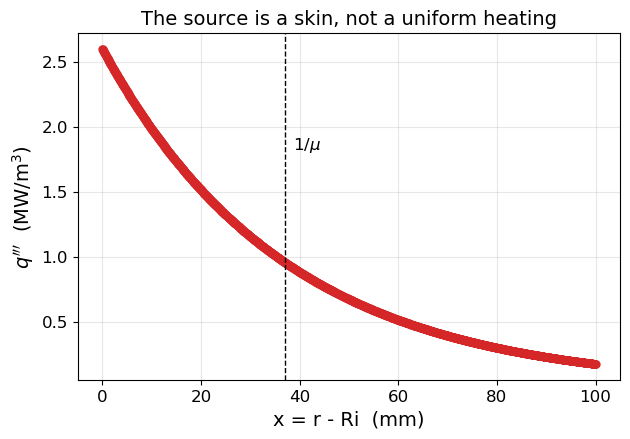

In [3]:
import numpy as np
import matplotlib.pyplot as plt

Ri, Ro, k_st = 0.300, 0.400, 20.0
mu, q0 = 27.0, 2.6e6
t = Ro - Ri
x = np.linspace(0, t, 2000)

print(f"q0 = {q0/1e6:.2f} MW/m3 at the inner wall,  mu = {mu} 1/m")
print(f"decay length 1/mu = {1000/mu:.1f} mm  in a {t*1e3:.0f} mm wall  ->  mu*t = {mu*t:.2f}")
print(f"source at the outer face / at the inner face = {np.exp(-mu*t):.3f}")
print(f"fraction of the total deposited in the first 1/mu = {(1-np.exp(-1))*100:.0f} %")
print(f"total deposited per unit area = {q0/mu*(1-np.exp(-mu*t)):.0f} W/m2")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(x*1e3, q0*np.exp(-mu*x)/1e6, lw=2.5, color='tab:red')
ax.axvline(1000/mu, ls='--', color='k', lw=1)
ax.annotate(r'$1/\mu$', xy=(1000/mu, q0/1e6*0.7), xytext=(6, 0),
            textcoords='offset points', fontsize=12)
ax.set_xlabel('x = r - Ri  (mm)'); ax.set_ylabel(r"$q'''$  (MW/m$^3$)")
ax.set_title('The source is a skin, not a uniform heating')
ax.grid(alpha=0.3); plt.show()

---
## 2. $T(x)$: the adiabatic outer face, and what it costs

The simplest model is a **slab with an adiabatic outer face**: all the gamma heat leaves
inwards, through the coolant. Solving $-k\,T'' = q_0'''e^{-\mu x}$ with $T(0)=T_i$ and
$T'(t)=0$:

$$T(x) - T_i = \frac{q_0'''}{k\mu^2}\Big[1 - e^{-\mu x} - \mu x\,e^{-\mu t}\Big]$$

It is the assumption behind the design curve of the assignment, which you use for the
preliminary estimate. It is not the thermal model of the assignment: that one puts $h_1$ on
the inner face and the $U_2$ you computed in G3 on the outer face, in cylindrical
coordinates (you solve it with z3st in §6b). So before trusting the preliminary estimate,
**check what the adiabatic face costs**: solve the same wall with exchange on both faces
and compare.

In [4]:
h1, U2, T_in, T_inf = 23858.0, 1.271, 560.0, 320.0     # from G3 (U2 referred to r = Ro)

# (a) the slab with an adiabatic outer face: the design-curve assumption
T_adia = T_in + q0/(k_st*mu**2)*(1 - np.exp(-mu*x) - mu*x*np.exp(-mu*t))

# (b) the boundary conditions of the assignment, h1 inside and U2 outside, by finite
#     differences. Solved numerically rather than by hand-derived constants -- a sign
#     slip in those is silent, and the energy balance below is what catches it.
def solve_both(tw, n=2001):
    xs = np.linspace(0, tw, n); dx = xs[1] - xs[0]
    q = q0*np.exp(-mu*xs)
    A = np.zeros((n, n)); b = np.zeros(n)
    for i in range(1, n-1):
        A[i, i-1:i+2] = [1.0, -2.0, 1.0]
        b[i] = -q[i]*dx**2/k_st
    A[0, 0], A[0, 1], b[0] = -(k_st/dx + h1), k_st/dx, -h1*T_in       # -k T'(0) = h1 (T_in - T0)
    A[-1, -2], A[-1, -1], b[-1] = -k_st/dx, k_st/dx + U2, U2*T_inf    #  k T'(t) = U2 (T_inf - Tt)
    return xs, A, np.linalg.solve(A, b)

xs, A, T_both = solve_both(t)
n = len(xs)

G = q0/mu*(1 - np.exp(-mu*t))
q_in, q_out = h1*(T_both[0] - T_in), U2*(T_both[-1] - T_inf)
print("energy balance -- the check that catches a sign error:")
print(f"  generated       {G:10.1f} W/m2")
print(f"  leaves inward   {q_in:10.1f} W/m2   ({100*q_in/G:5.1f} %)")
print(f"  leaves outward  {q_out:10.1f} W/m2   ({100*q_out/G:5.1f} %)")
print(f"  closure         {100*(q_in+q_out)/G - 100:+9.3f} %\n")
print(f"  -> the insulated face carries {100*q_out/G:.1f} % of the heat.")
print("     That, not convenience, is what makes the adiabatic-outer design curve")
print("     a fair preliminary estimate.")
print(f"\n  dT: adiabatic model {T_adia.max()-T_adia.min():6.1f} K"
      f"   vs both faces {T_both.max()-T_both.min():6.1f} K"
      f"   ({100*abs(T_both.max()-T_both.min())/(T_adia.max()-T_adia.min())-100:+.1f} %)")

energy balance -- the check that catches a sign error:
  generated          89824.7 W/m2
  leaves inward      89278.3 W/m2   ( 99.4 %)
  leaves outward       477.0 W/m2   (  0.5 %)
  closure            -0.077 %

  -> the insulated face carries 0.5 % of the heat.
     That, not convenience, is what makes the adiabatic-outer design curve
     a fair preliminary estimate.

  dT: adiabatic model  134.0 K   vs both faces  131.6 K   (-1.8 %)


---
## 3. Where is the maximum?

Now the question the syllabus asks. Compare three walls: no source at all, the source with
an adiabatic outer face, and the source with both faces exchanging.

case                                   T(0)     T(t)    T_max   at x (mm)    T_avg
no source                             560.0    558.5    560.0         0.0    559.2
source, adiabatic outer               560.0    694.0    694.0       100.0    663.3
source, both faces exchanging         563.7    695.3    695.4        97.4    665.8

Heat fluxes with no volumetric source (positive = leaving the wall):
  inner surface    -0.3031 kW/m2
  outer surface     0.3031 kW/m2
  sum 0.00 % of either: with no source, what enters one face leaves the other.
  Note the SIGN: heat now flows INWARD (the containment is colder), whereas
  with the source both faces carry heat OUT -- 89.3 and 0.477 kW/m2.

Without the source the wall sits BETWEEN its two fluids and the profile is
monotonic. With it, the wall runs 3.7 K ABOVE its own coolant at
the inner face and 135 K above it at the peak.
A wall hotter than the fluid cooling it is the signature of internal generation.


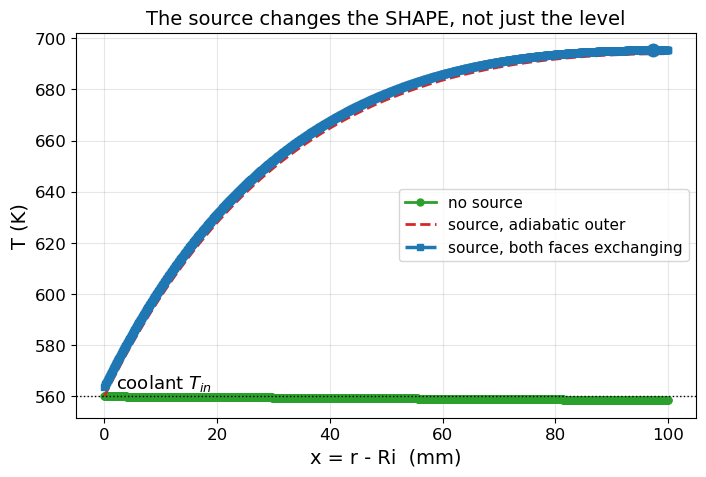

In [5]:
# no source: pure conduction between the two fluids, same h1 and U2
A0 = A.copy(); b0 = np.zeros(n)
b0[0], b0[-1] = -h1*T_in, U2*T_inf
T_nosrc = np.linalg.solve(A0, b0)

i_b = int(np.argmax(T_both))

# The average metal temperature THROUGH THE THICKNESS (NCA-2142.1(b) calls it the
# "mean metal temperature"). Volume-weighted over cylindrical shells,
# integral(T r dr)/integral(r dr) -- the quantity the design temperature is defined on.
# It is not the average of the two surface values, and on a profile with an interior
# peak it is not close to it either.
def T_avg(T, xgrid):
    r = Ri + xgrid
    return np.trapezoid(T*r, r)/np.trapezoid(r, r)

print(f"{'case':34}{'T(0)':>9}{'T(t)':>9}{'T_max':>9}{'at x (mm)':>12}{'T_avg':>9}")
print(f"{'no source':34}{T_nosrc[0]:9.1f}{T_nosrc[-1]:9.1f}{T_nosrc.max():9.1f}"
      f"{xs[int(np.argmax(T_nosrc))]*1e3:12.1f}{T_avg(T_nosrc, xs):9.1f}")
print(f"{'source, adiabatic outer':34}{T_adia[0]:9.1f}{T_adia[-1]:9.1f}{T_adia.max():9.1f}"
      f"{x[int(np.argmax(T_adia))]*1e3:12.1f}{T_avg(T_adia, x):9.1f}")
print(f"{'source, both faces exchanging':34}{T_both[0]:9.1f}{T_both[-1]:9.1f}"
      f"{T_both.max():9.1f}{xs[i_b]*1e3:12.1f}{T_avg(T_both, xs):9.1f}")

# The assignment asks for the FLUX in this case, not only the profile.
q_in_0, q_out_0 = h1*(T_nosrc[0] - T_in), U2*(T_nosrc[-1] - T_inf)
print("\nHeat fluxes with no volumetric source (positive = leaving the wall):")
print(f"  inner surface  {q_in_0/1e3:9.4f} kW/m2")
print(f"  outer surface  {q_out_0/1e3:9.4f} kW/m2")
print(f"  sum {abs(q_in_0 + q_out_0)/max(abs(q_out_0), 1e-12)*100:.2f} % of either: with no source, what enters one face leaves the other.")
print(f"  Note the SIGN: heat now flows INWARD (the containment is colder), whereas")
print(f"  with the source both faces carry heat OUT -- {q_in/1e3:.1f} and {q_out/1e3:.3f} kW/m2.")

print(f"\nWithout the source the wall sits BETWEEN its two fluids and the profile is")
print(f"monotonic. With it, the wall runs {T_both[0]-T_in:.1f} K ABOVE its own coolant at")
print(f"the inner face and {T_both.max()-T_in:.0f} K above it at the peak.")
print("A wall hotter than the fluid cooling it is the signature of internal generation.")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(xs*1e3, T_nosrc, lw=2, color='tab:green', label='no source')
ax.plot(x*1e3, T_adia, '--', lw=2, color='tab:red', label='source, adiabatic outer')
ax.plot(xs*1e3, T_both, lw=2.5, color='tab:blue', label='source, both faces exchanging')
ax.axhline(T_in, color='k', ls=':', lw=1)
ax.annotate('coolant $T_{in}$', xy=(2, T_in), xytext=(0, 6), textcoords='offset points')
ax.plot(xs[i_b]*1e3, T_both[i_b], 'o', ms=9, color='tab:blue')
ax.set_xlabel('x = r - Ri  (mm)'); ax.set_ylabel('T (K)')
ax.set_title('The source changes the SHAPE, not just the level')
# Exported for the course notes (figures/README.md: one owner per figure).
import os
# Export for the course notes. The target is named by an environment variable
# that only the author sets, so this is a no-op everywhere else -- without the
# guard the cell would raise FileNotFoundError for every student.
_cn = os.environ.get("NDT_COURSE_NOTES_FIGURES", "")
if os.path.isdir(_cn):
    plt.savefig(os.path.join(_cn, "14_wall_temperature.pdf"), bbox_inches="tight")
ax.legend(); ax.grid(alpha=0.3); plt.show()

---
## 4. Closing the design conditions

This profile is not only an answer to "how hot does the wall get". It is what lets you
**fix the design temperature**, which until now you have only assumed.

**NCA-2142.1(b)**, to which **NB-3112.2(a)** refers: the design temperature shall not be less than the maximum "*mean metal
temperature through the thickness*" of the part considered, for the conditions where Level A
Service Limits apply. And where a component is heated *by internal heat generation* (a
gamma field is exactly that), **NB-3112.2(c)** requires the effect of that heating to be included.

Three consequences, and each one is a place where groups go wrong:

- it is the **average** through the thickness, not the peak. The peak belongs to the
  maximum temperature limit of the material (Table 1 of your assignment, NB-1120), which it
  is compared with, and to the thermal stress, not to Table 2;
- it is a **metal** temperature, not a coolant temperature;
- it comes from **normal operation**. The accidental scenarios set the design *pressure*
  only.

So the thickness you started from is **tentative** by construction, and this is where it closes:
take the average, re-read the allowable and re-enter the external-pressure charts (NB-3133)
at that temperature, and check whether the wall you
chose still stands.

These checks use the ASME rules of the design conditions. If you have not met these rules
yet, compute the average now and come back to this section later.

In [6]:
# --- closing the design conditions ------------------------------------------------
# Neutral numbers again: the sizing procedure (Di = 0.600 m, internal design pressure
# 6.0 MPa) applied to the 100 mm wall of THIS notebook -- the wall whose temperature field
# was just computed. The temperature field and the sizing must belong to the same wall.
# The material table is in the ASME format -- READ BY ROW, never interpolated.
# "350" means: this value holds above 300 and up to 350 included ("not exceeding",
# as in II-D Table Y-1).
# The table gives the yield strength; the allowable is derived from it and from Su:
# Sm = min(Su(T)/3, 2 Sy(T)/3), ASME II-D Mandatory Appendix 2, para 2-110.
T_rows  = np.array([250.0, 300.0, 350.0, 400.0, 450.0])      # degC, "not exceeding"
Sy_rows = np.array([207.0, 201.0, 195.0, 183.0, 165.0])      # MPa
Su_n    = 414.0                                              # MPa, constant here
Sm_rows = np.minimum(Su_n/3.0, 2.0*Sy_rows/3.0)

def Sm_of(T_C):
    """The row a temperature falls in. A lookup, not an interpolation."""
    if T_C > T_rows[-1]:
        raise ValueError("outside the table: the material is not qualified there")
    return float(Sm_rows[np.searchsorted(T_rows, T_C, side="left")])

Di, P_int = 0.600, 6.0e6            # m, Pa -- neutral
T_tentative = 290.0                 # degC, a tentative design temperature, declared before T(r) is known
T_design = T_avg(T_both, xs) - 273.15    # degC, computed above, on the 100 mm wall

def t_min(Sm_MPa):                  # NB-3324.1, on the mean radius
    return P_int*(Di/2)/(Sm_MPa*1e6 - P_int/2)

print(f"tentative design temperature    {T_tentative:6.1f} degC -> row {T_rows[np.searchsorted(T_rows, T_tentative, side='left')]:.0f},"
      f" Sm = {Sm_of(T_tentative):5.1f} MPa -> t_min = {t_min(Sm_of(T_tentative))*1e3:5.1f} mm")
print(f"average metal temperature       {T_design:6.1f} degC -> row {T_rows[np.searchsorted(T_rows, T_design, side='left')]:.0f},"
      f" Sm = {Sm_of(T_design):5.1f} MPa -> t_min = {t_min(Sm_of(T_design))*1e3:5.1f} mm")
print(f"\npeak metal temperature          {T_both.max()-273.15:6.1f} degC  <- NOT the design temperature."
      f" It is the one compared with the maximum temperature limit of the material (NB-1120).")

growth = t_min(Sm_of(T_design))/t_min(Sm_of(T_tentative)) - 1
print(f"\nThe wall the Code demands grew by {100*growth:.1f} % when the temperature stopped being a guess.")
print(f"This wall is {t*1e3:.0f} mm against t_min = {t_min(Sm_of(T_design))*1e3:.1f} mm:"
      f" {'it stands' if t >= t_min(Sm_of(T_design)) else 'it does NOT stand'}.")

# The loop: revising the thickness changes the temperature field. Which way?
xs3, _, T3 = solve_both(1.03*t)
print(f"\nThe same wall 3 % thicker ({1.03*t*1e3:.0f} mm): average temperature"
      f" {T_avg(T3, xs3) - 273.15:.1f} degC, {T_avg(T3, xs3) - T_avg(T_both, xs):+.1f} K.")
print("A thicker wall absorbs more of the gamma source, so it runs HOTTER, not cooler.")

tentative design temperature     290.0 degC -> row 300, Sm = 134.0 MPa -> t_min =  13.7 mm
average metal temperature        392.7 degC -> row 400, Sm = 122.0 MPa -> t_min =  15.1 mm

peak metal temperature           422.2 degC  <- NOT the design temperature. It is the one compared with the maximum temperature limit of the material (NB-1120).

The wall the Code demands grew by 10.1 % when the temperature stopped being a guess.
This wall is 100 mm against t_min = 15.1 mm: it stands.



The same wall 3 % thicker (103 mm): average temperature 395.0 degC, +2.4 K.
A thicker wall absorbs more of the gamma source, so it runs HOTTER, not cooler.


**The loop, and when it does not close.** Revising the thickness changes the profile,
which changes the average, which changes the allowable. A thicker wall absorbs more of
the gamma source and runs hotter: on this wall, 3 % more thickness raises the average by
about 2.4 K. That is small next to the allowable table, which steps only at its own row
edges, so one pass usually settles it. What you must not do is skip the pass and carry
the guess forward.

The loop can also fail to close. A material comes with a temperature limit of its own,
stated with its data, and NB-3112.4 forbids using it above that temperature. If the design
temperature exceeds it, no thickness recovers it. Adding steel adds gamma heating, so the
wall only gets hotter. The thickness is not the lever there, and the report has to say so.

Do not read that limit off the allowable table. The last row of a table is where the
*table* stops (`Sm_of` above refuses anything past its last edge), and it need not
coincide with the temperature limit of the material. Take the limit from where it is
stated.

---
## 5. Slab and cylinder: a warning

The model above is a **slab**: it drops the curvature of the wall, and it uses a plain
$e^{-\mu x}$ for the source. The finite-element model of §6b does neither: z3st
deposits the gamma energy with the cylindrical profile $K_0(\mu r)/K_0(\mu R_i)$.

So your analytical $T(r)$ and your FE $T(r)$ **will not agree exactly**, and the
difference is *physical*: two slightly different problems, not a numerical error. It is
about 1 % on the peak stress for a wall like this one. Knowing that in advance is what
will stop you spending a day refining a mesh to chase it.

---
## 6. A wall with a liner

A vessel wetted by the coolant is usually protected by a thin austenitic layer bonded to its
inner face, the **liner**. Two faces now need names: the **wetted surface** is the inner face
of the liner, the one the coolant touches and the gamma flux enters; the **vessel inner
surface** is the interface between liner and vessel.

Add a neutral liner to the wall of this notebook: $t_L$ = 4 mm, $k_L$ = 16 W/m K. Its
attenuation coefficient is taken equal to that of the vessel. At these photon energies the
attenuation per unit mass follows the number of electrons per gram, which is nearly the same
for a ferritic and an austenitic steel (both are mostly iron, and Cr and Ni have a similar
ratio $Z/A$), and the two densities differ by a few per cent. The source keeps its exponential
law, now counted from the wetted surface, so the vessel inner surface receives
$q_0'''\,e^{-\mu t_L}$.

The model is the one of §2, $h_1$ on the wetted surface and $U_2$ on the outer face, with
two layers in series. The same finite differences, with $k$ now depending on $x$.

source at the wetted surface             2.600 MW/m3
source at the vessel inner surface       2.334 MW/m3   (x exp(-mu t_L) = 0.898)
source at the vessel outer surface       0.157 MW/m3



energy balance of the lined wall: closure -0.076 %

                                no liner     lined   change
wetted surface T (K)               563.7     563.8     +0.0
vessel inner surface T (K)         563.7     585.0    +21.3
vessel outer surface T (K)         695.3     702.8     +7.5
vessel peak T (K)                  695.4     702.9     +7.5
vessel average T (K)               665.8     676.5    +10.7
vessel dT, peak - inner (K)        131.6     117.9    -13.8

peak position in the vessel: 97.4 mm without liner, 97.0 mm with it (from the vessel inner surface)


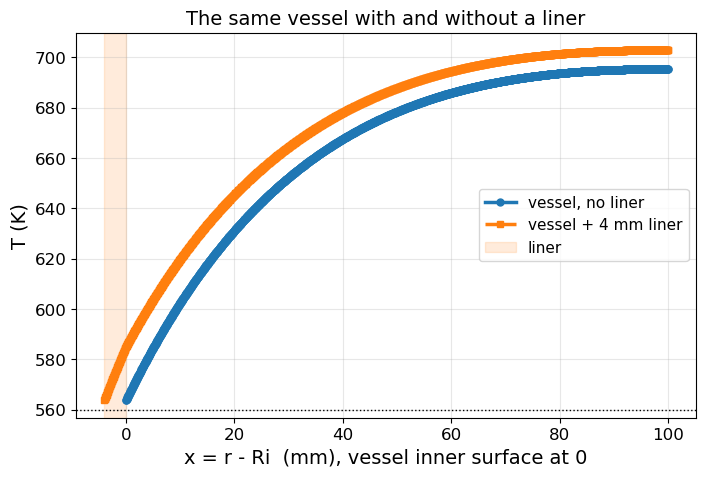

In [7]:
# --- the same wall with a liner: two layers in series --------------------------------
# A neutral liner, 4 mm of austenitic steel with k = 16 W/m K, bonded on the inner face.
# The vessel is unchanged: same Ri, Ro, k_st. The wetted surface moves inwards by t_L.
t_L, k_L = 0.004, 16.0
mu_L = mu          # same attenuation coefficient as the ferritic wall (see the text above)

print(f"source at the wetted surface            {q0/1e6:6.3f} MW/m3")
print(f"source at the vessel inner surface      {q0*np.exp(-mu_L*t_L)/1e6:6.3f} MW/m3"
      f"   (x exp(-mu t_L) = {np.exp(-mu_L*t_L):.3f})")
print(f"source at the vessel outer surface      {q0*np.exp(-mu_L*t_L - mu*t)/1e6:6.3f} MW/m3\n")

def solve_layers(t_L, k_L, n=2001):
    # Same finite differences as solve_both, with k now a function of x. The grid puts
    # the liner/vessel interface on a node, and k is taken at the half-points between
    # nodes, so the heat flux is continuous across the interface by construction.
    N = int(round(t_L/(t/(n - 1))))           # liner cells, same spacing as the vessel
    m = n + N
    xs_ = np.linspace(0, t_L + t, m); dx = xs_[1] - xs_[0]
    q = np.where(xs_ <= t_L, q0*np.exp(-mu_L*xs_), q0*np.exp(-mu_L*t_L - mu*(xs_ - t_L)))
    kh = np.where(0.5*(xs_[1:] + xs_[:-1]) < t_L, k_L, k_st)    # k at the half-points
    A_ = np.zeros((m, m)); b_ = np.zeros(m)
    for i in range(1, m-1):
        A_[i, i-1:i+2] = [kh[i-1], -(kh[i-1] + kh[i]), kh[i]]
        b_[i] = -q[i]*dx**2
    A_[0, 0], A_[0, 1], b_[0] = -(kh[0]/dx + h1), kh[0]/dx, -h1*T_in
    A_[-1, -2], A_[-1, -1], b_[-1] = -kh[-1]/dx, kh[-1]/dx + U2, U2*T_inf
    return xs_, N, np.linalg.solve(A_, b_)

# with no liner the two-layer solver must return the curve of section 2, to round-off
_, _, T_chk = solve_layers(0.0, k_L)
assert np.allclose(T_chk, T_both, atol=1e-8), "two-layer solver disagrees with solve_both"

xl, N, T_lin = solve_layers(t_L, k_L)
xv, Tv = xl[N:] - t_L, T_lin[N:]         # the vessel part, x measured from Ri as before

G_l = q0/mu_L*(1 - np.exp(-mu_L*t_L)) + q0*np.exp(-mu_L*t_L)/mu*(1 - np.exp(-mu*t))
out = h1*(T_lin[0] - T_in) + U2*(T_lin[-1] - T_inf)
print(f"energy balance of the lined wall: closure {100*out/G_l - 100:+.3f} %\n")

print(f"{'':30}{'no liner':>10}{'lined':>10}{'change':>9}")
for lab, a, b in (("wetted surface T (K)",        T_both[0],               T_lin[0]),
                  ("vessel inner surface T (K)",  T_both[0],               Tv[0]),
                  ("vessel outer surface T (K)",  T_both[-1],              Tv[-1]),
                  ("vessel peak T (K)",           T_both.max(),            Tv.max()),
                  ("vessel average T (K)",        T_avg(T_both, xs),       T_avg(Tv, xv)),
                  ("vessel dT, peak - inner (K)", T_both.max()-T_both[0],  Tv.max()-Tv[0])):
    print(f"{lab:30}{a:10.1f}{b:10.1f}{b-a:+9.1f}")
print(f"\npeak position in the vessel: {xs[np.argmax(T_both)]*1e3:.1f} mm without liner,"
      f" {xv[np.argmax(Tv)]*1e3:.1f} mm with it (from the vessel inner surface)")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(xs*1e3, T_both, lw=2.5, color='tab:blue', label='vessel, no liner')
ax.plot((xl - t_L)*1e3, T_lin, lw=2.5, color='tab:orange', label=f'vessel + {t_L*1e3:.0f} mm liner')
ax.axvspan(-t_L*1e3, 0, color='tab:orange', alpha=0.15, label='liner')
ax.axhline(T_in, color='k', ls=':', lw=1)
ax.set_xlabel('x = r - Ri  (mm), vessel inner surface at 0'); ax.set_ylabel('T (K)')
ax.set_title('The same vessel with and without a liner')
ax.legend(); ax.grid(alpha=0.3); plt.show()

**Two effects, and they pull in opposite directions.**

- **A thermal resistance in series.** Almost all the gamma heat leaves through the wetted
  surface (§2). With a liner it must first cross $t_L/k_L$ of extra resistance, in a material
  that conducts worse than the vessel steel, so the whole vessel is lifted above the wetted
  surface: the vessel inner surface is no longer at the temperature of the wetted surface.
- **Attenuation before the vessel.** The liner absorbs part of the flux, so the source in the
  vessel is smaller by $e^{-\mu t_L}$ everywhere, and so is the temperature difference across
  the vessel.

The first acts on the **level** of the vessel temperature, the second on its **shape**. Which
one wins, for the average and for the peak, depends on $t_L$, $k_L$, $\mu$ and the source:
the table above answers it for this neutral wall only. Note also that the wetted surface
hardly moves: its temperature is set by $h_1$ and by the total heat leaving, which the liner
barely changes.

**On your wall.** Compute the source at the wetted surface, at the vessel inner surface and
at the vessel outer surface, and $T(r)$ across liner and vessel, next to the same vessel with
the liner removed. For each quantity that changes (vessel average, vessel peak, the
difference across the vessel) say which of the two effects moves it, and in which direction.

**Does the Code let you drop the liner here?** NB-3122.3 allows an integrally bonded cladding
of at most 10 % of the total thickness to be neglected. Read the clause: which checks is that
permission written for, and is the temperature field of item 6, the one your design
temperature and the temperature limit are read from, one of them?

---
## 6b. The same lined wall in Z3ST, in cylindrical coordinates

Item 6 of the assignment asks for $T(r)$ from the heat equation **in cylindrical coordinates,
solved with Z3ST**; the slab of §6 is the hand check. The case is
`cases/G4_lined_wall_thermal`, the wall of §6 with the same neutral numbers. Open its files
before running it, because on your own wall you will edit exactly these:

- `geometry.yaml` and `mesh.geo`: three radii, the **wetted surface** $R_i$ = 0.296 m, the
  **vessel inner surface** $R_m$ = 0.300 m, the vessel outer surface $R_o$ = 0.400 m. The
  interface is a mesh line, so every cell belongs to one material.
- `liner_neutral.yaml` and `steel_neutral.yaml`: one card per material, $k$ = 16 and 20 W/m K.
  Both carry the **same** `gamma_heating`, the source at the wetted surface, and the same
  $\mu$: Z3ST counts the profile $K_0(\mu r)/K_0(\mu R_i)$ from $R_i$ in both, so the vessel
  receives the attenuated source by itself. Do not put $q_0''' e^{-\mu t_L}$ in the steel card.
- `boundary_conditions.yaml`: $h_1$ on the wetted surface, $U_2$ on the outer face, each under
  the material it touches.
- `input.yaml`: `thermal: true`, `mechanical: false`. Day 3 switches the mechanics on in this
  same case.

The case checks itself against an independent reference (the same $K_0$ source, integrated by
quadrature through the two layers).

In [8]:
# --- solve the lined wall in Z3ST: mesh -> solve -> self-check --------------------
LABS = ndt_setup.labs_root()
CASE_LW = os.path.join(LABS, 'cases', 'G4_lined_wall_thermal')
ndt_setup.run_case(CASE_LW)


$ gmsh mesh.geo -2 -o mesh.msh


Info    : Running '~/miniconda3/envs/z3st/bin/gmsh mesh.geo -2 -o mesh.msh' [Gmsh 4.15.2, 1 node, max. 1 thread]
Info    : Started on Tue Oct 20 19:39:42 2026
Info    : Reading 'mesh.geo'...
Info    : Done reading 'mesh.geo'
Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 20%] Meshing curve 2 (Line)
Info    : [ 30%] Meshing curve 3 (Line)
Info    : [ 50%] Meshing curve 4 (Line)
Info    : [ 60%] Meshing curve 5 (Line)
Info    : [ 80%] Meshing curve 6 (Line)
Info    : [ 90%] Meshing curve 7 (Line)
Info    : Done meshing 1D (Wall 0.000422891s, CPU 0.00014s)
Info    : Meshing 2D...
Info    : [  0%] Meshing surface 1 (Transfinite)
Info    : [ 60%] Meshing surface 2 (Transfinite)
Info    : Done meshing 2D (Wall 0.002061s, CPU 0s)
Info    : 4469 nodes 4662 elements
Info    : Writing 'mesh.msh'...
Info    : Done writing 'mesh.msh'
Info    : Stopped on Tue Oct 20 19:39:42 2026 (From start: Wall 0.0268736s, CPU 0.4593s)

$ ~/miniconda3/envs/z3st/bin/python3.12 -m z3st

onfig initializer

  → Geometry            : geometry.yaml
  → Mesh                : mesh.msh
  → Boundary conditions : boundary_conditions.yaml
  → Time steps          : 1
  → Regime              : axisymmetric
  → Models active       :
      thermal    → ON
      mechanical → OFF
      damage     → OFF
      cluster    → OFF
      plasticity → OFF
      contact    → OFF
      porosity   → OFF
      fission_gas → OFF
  → Gap conductance     : None (value = 0.0)



### FiniteElementSetup initializer

Mechanical element order: 1
Thermal function space (V_t): FunctionSpace(<Mesh #0>, Basix element (P, quadrilateral, 1, gll_warped, unset, False, float64, []))
Mechanical function space (V_m): FunctionSpace(<Mesh #0>, blocked element (Basix element (P, quadrilateral, 1, gll_warped, unset, False, float64, []), (2,)))
Scalar function space (Q): FunctionSpace(<Mesh #0>, Basix element (P, quadrilateral, 0, gll_warped, unset, True, float64, []))
[Solver] initializer
  Applied relaxation factor:


[INFO] 1040 of 1041 probe points inside the mesh

                                    z3st  reference
  wetted surface                  563.96     563.96  K
  vessel inner surface            586.16     586.15  K
  vessel outer surface            702.94     702.93  K
  maximum                         702.98     702.97  K
  max at r - Rm (mm)               97.00      96.60
  vessel average                  677.70     677.69  K

  where the gamma heat goes (reference, per metre of height):
    generated         176808.2 W/m
    wetted surface    175585.0 W/m   (99.31 %)
    outer surface       1223.2 W/m   ( 0.69 %)
[INFO] Plot saved in: ~/ndt-labs/cases/G4_lined_wall_thermal/output/verification.png

Pass/Fail check (tolerance = 1.0e-02)
  L2_error_temperature → rel err = 5.45e-05  → PASS
  T_wetted_surface   → rel err = 6.29e-05  → PASS
  T_vessel_inner_surface → rel err = 8.32e-05  → PASS
  T_max              → rel err = 5.89e-05  → PASS
  T_vessel_average   → rel err = 3.72e-05  → PASS

True

                               slab (sec. 6)  Z3ST cylinder    diff
wetted surface T (K)                   563.8          564.0    +0.2
vessel inner surface T (K)             585.0          586.2    +1.1
vessel peak T (K)                      702.9          703.0    +0.1
vessel average T (K)                   676.5          677.7    +1.2


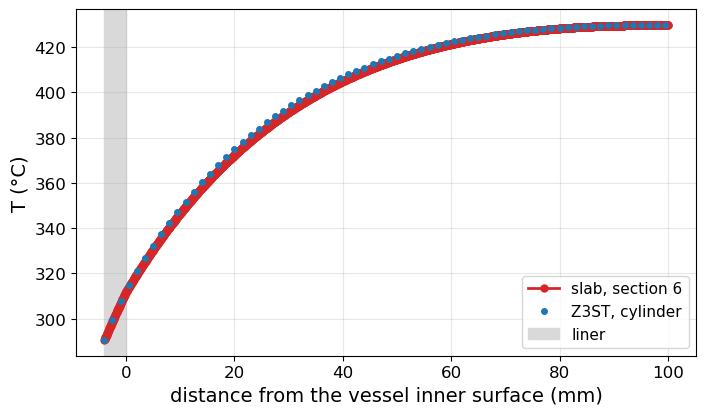

In [9]:
# --- the cylinder (Z3ST) against the slab of section 6 -----------------------------
import pyvista as pv, yaml
g = yaml.safe_load(open(os.path.join(CASE_LW, 'geometry.yaml')))
Ri_w, Rm_w, Ro_w, Lz_w = g['Ri'], g['Rm'], g['Ro'], g['Lz']
line = pv.read(os.path.join(CASE_LW, 'output', 'fields.vtu')).sample_over_line(
    (Ri_w, Lz_w/2, 0.0), (Ro_w, Lz_w/2, 0.0), resolution=1040)
okp = np.asarray(line['vtkValidPointMask']).astype(bool) & (np.asarray(line['Temperature']) > 1.0)
r_z, T_z = line.points[okp, 0], np.asarray(line['Temperature'])[okp]
o = np.argsort(r_z); r_z, T_z = r_z[o], T_z[o]

mv = r_z >= Rm_w                                     # the vessel only, for the average
avg_z = np.trapezoid(T_z[mv]*r_z[mv], r_z[mv])/np.trapezoid(r_z[mv], r_z[mv])

print(f"{'':30}{'slab (sec. 6)':>14}{'Z3ST cylinder':>15}{'diff':>8}")
for lab, a, b in (("wetted surface T (K)",       T_lin[0],        T_z[0]),
                  ("vessel inner surface T (K)", Tv[0],           np.interp(Rm_w, r_z, T_z)),
                  ("vessel peak T (K)",          Tv.max(),        T_z.max()),
                  ("vessel average T (K)",       T_avg(Tv, xv),   avg_z)):
    print(f"{lab:30}{a:14.1f}{b:15.1f}{b - a:+8.1f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot((xl - t_L)*1e3, T_lin - 273.15, lw=2, color='tab:red', label='slab, section 6')
ax.plot((r_z - Rm_w)[::15]*1e3, T_z[::15] - 273.15, 'o', ms=4, color='tab:blue', label='Z3ST, cylinder')
ax.axvspan(-t_L*1e3, 0, color='0.85', label='liner')
ax.set_xlabel('distance from the vessel inner surface (mm)'); ax.set_ylabel('T (°C)')
ax.grid(alpha=0.3); ax.legend(); plt.show()

The two models differ by about a kelvin here: same source law, same boundary conditions, one
of them with the curvature of the wall and the $K_0$ profile, the other without. Whether the
slab is on the safe side of the cylinder, and why, is a question for your own wall (open
point 6 of the assignment), not for this one.

**On your wall.** The two cells of §7 build this case on your numbers: write them in the
first, run the second. From the solution read what item 6 asks: the temperature at the
wetted surface and at the vessel inner and outer surfaces, the maximum and **where** it is,
and the **average across the vessel thickness**, which is the design temperature of item 8.
Then set `MY_tL = 0` and run the two cells again: that is the same vessel with the liner
removed, its inner surface now the wetted surface, receiving the source unattenuated.
Compare the two, as item 6 asks.

**Save the case when you finish**: the mechanical analysis starts from it.

In [10]:
# ---- YOUR WALL: write your numbers here, then run this cell and the next -----------
# The default values are the neutral wall of this notebook. Change the thickness first:
# the cell below builds the Z3ST case on whatever you write here and solves it.
MY_t    = 0.100      # m    vessel thickness  <-- your tentative thickness
MY_Ri   = 0.300      # m    vessel inner radius (the liner sits inside it)
MY_tL   = 0.004      # m    liner thickness (0: the same vessel without the liner)
MY_k, MY_kL   = 20.0, 16.0       # W/(m K)  vessel, liner
MY_q0, MY_mu  = 2.6e6, 27.0      # W/m3 at the wetted surface, 1/m
MY_h1, MY_Tin = 23858.0, 560.0   # W/(m2 K), K   inner film and coolant (G3)
MY_U2, MY_Tinf = 1.271, 320.0    # W/(m2 K), K   outer, referred to r = Ro (G3)



$ gmsh mesh.geo -2 -o mesh.msh


Info    : Running '~/miniconda3/envs/z3st/bin/gmsh mesh.geo -2 -o mesh.msh' [Gmsh 4.15.2, 1 node, max. 1 thread]
Info    : Started on Tue Oct 20 19:39:52 2026
Info    : Reading 'mesh.geo'...
Info    : Done reading 'mesh.geo'
Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 20%] Meshing curve 2 (Line)
Info    : [ 30%] Meshing curve 3 (Line)
Info    : [ 50%] Meshing curve 4 (Line)
Info    : [ 60%] Meshing curve 5 (Line)
Info    : [ 80%] Meshing curve 6 (Line)
Info    : [ 90%] Meshing curve 7 (Line)
Info    : Done meshing 1D (Wall 0.00221901s, CPU 0.000454s)
Info    : Meshing 2D...
Info    : [  0%] Meshing surface 1 (Transfinite)
Info    : [ 60%] Meshing surface 2 (Transfinite)
Info    : Done meshing 2D (Wall 0.00226366s, CPU 0.000553s)
Info    : 4469 nodes 4662 elements
Info    : Writing 'mesh.msh'...
Info    : Done writing 'mesh.msh'
Info    : Stopped on Tue Oct 20 19:39:52 2026 (From start: Wall 0.0298679s, CPU 0.459945s)

$ ~/miniconda3/envs/z3st/bin/python3

onfig initializer

  → Geometry            : geometry.yaml
  → Mesh                : mesh.msh
  → Boundary conditions : boundary_conditions.yaml
  → Time steps          : 1
  → Regime              : axisymmetric
  → Models active       :
      thermal    → ON
      mechanical → OFF
      damage     → OFF
      cluster    → OFF
      plasticity → OFF
      contact    → OFF
      porosity   → OFF
      fission_gas → OFF
  → Gap conductance     : None (value = 0.0)



### FiniteElementSetup initializer

Mechanical element order: 1
Thermal function space (V_t): FunctionSpace(<Mesh #0>, Basix element (P, quadrilateral, 1, gll_warped, unset, False, float64, []))
Mechanical function space (V_m): FunctionSpace(<Mesh #0>, blocked element (Basix element (P, quadrilateral, 1, gll_warped, unset, False, float64, []), (2,)))
Scalar function space (Q): FunctionSpace(<Mesh #0>, Basix element (P, quadrilateral, 0, gll_warped, unset, True, float64, []))
[Solver] initializer
  Applied relaxation factor:


[INFO] 1040 of 1041 probe points inside the mesh

                                    z3st  reference
  wetted surface                  563.96     563.96  K
  vessel inner surface            586.16     586.15  K
  vessel outer surface            702.94     702.93  K
  maximum                         702.98     702.97  K
  max at r - Rm (mm)               97.00      96.60
  vessel average                  677.70     677.69  K

  where the gamma heat goes (reference, per metre of height):
    generated         176808.2 W/m
    wetted surface    175585.0 W/m   (99.31 %)
    outer surface       1223.2 W/m   ( 0.69 %)
[INFO] Plot saved in: ~/ndt-labs/ndt-work/my_vessel/output/verification.png

Pass/Fail check (tolerance = 1.0e-02)
  L2_error_temperature → rel err = 5.45e-05  → PASS
  T_wetted_surface   → rel err = 6.29e-05  → PASS
  T_vessel_inner_surface → rel err = 8.32e-05  → PASS
  T_max              → rel err = 5.89e-05  → PASS
  T_vessel_average   → rel err = 3.72e-05  → PASS

[SUMMAR

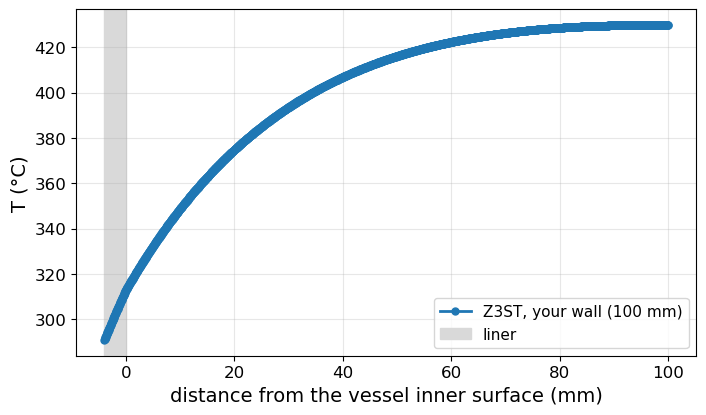

In [11]:
# ---- build the case on YOUR wall, solve it, and read the numbers -----------------
# Copies the neutral case of section 6b, writes your numbers into its files, and runs
# mesh -> solve -> self-check. The self-check rebuilds the analytical profile from the
# same files, so a PASS means Z3ST solved the wall you wrote, not the neutral one.
# Re-running this cell rebuilds the case from scratch: edit the cell above, not the files.
import re, shutil

assert MY_t > 0 and MY_tL >= 0, 'thicknesses cannot be negative'
# No liner: built as a 0.01 mm layer of the vessel steel, so the case keeps its two
# regions and the result is the bare vessel to within that layer. Saved apart, so it
# does not overwrite the lined vessel the mechanics starts from.
tL, kL = (MY_tL, MY_kL) if MY_tL > 0 else (1e-5, MY_k)
MY_CASE = ndt_setup.workdir('my_vessel' if MY_tL > 0 else 'my_vessel_no_liner')
if os.path.isdir(MY_CASE):
    shutil.rmtree(MY_CASE)
shutil.copytree(CASE_LW, MY_CASE, ignore=shutil.ignore_patterns('output', 'mesh.msh', 'log_*'))

def _set(fname, key, value, geo=False):
    # replace `key: old` (yaml) or `key = old;` (gmsh), keeping the comment that follows
    p = os.path.join(MY_CASE, fname)
    pat = rf'^({key}\s*=\s*)[^;]+;' if geo else rf'^({key}:\s*)\S+'
    new, n = re.subn(pat, rf'\g<1>{value}' + (';' if geo else ''), open(p).read(), flags=re.M)
    assert n == 1, f'{key} not found in {fname}'
    open(p, 'w').write(new)

Ri_w, Rm_w, Ro_w = MY_Ri - tL, MY_Ri, MY_Ri + MY_t
for key, val in (('Ri', Ri_w), ('Rm', Rm_w), ('Ro', Ro_w)):
    _set('geometry.yaml', key, f'{val:.6g}')
    _set('mesh.geo', key, f'{val:.6g}', geo=True)
_set('mesh.geo', 'n_L', max(5, round(tL/0.0005) + 1), geo=True)   # 0.5 mm cells
_set('mesh.geo', 'n_V', max(21, round(MY_t/0.001) + 1), geo=True)    # 1 mm cells
for card, k in (('steel_neutral.yaml', MY_k), ('liner_neutral.yaml', kL)):
    _set(card, 'k', k)
    _set(card, 'mu_gamma', MY_mu)
    _set(card, 'gamma_heating', f'{MY_q0:.6g}')
bc = os.path.join(MY_CASE, 'boundary_conditions.yaml')
b = yaml.safe_load(open(bc))
b['thermal']['liner'][0].update(h_conv=MY_h1, T_ext=MY_Tin)
b['thermal']['steel'][0].update(h_conv=MY_U2, T_ext=MY_Tinf)
yaml.safe_dump(b, open(bc, 'w'), sort_keys=False)

ndt_setup.run_case(MY_CASE)

line = pv.read(os.path.join(MY_CASE, 'output', 'fields.vtu')).sample_over_line(
    (Ri_w, Lz_w/2, 0.0), (Ro_w, Lz_w/2, 0.0), resolution=2000)
okp = np.asarray(line['vtkValidPointMask']).astype(bool) & (np.asarray(line['Temperature']) > 1.0)
r_m, T_m = line.points[okp, 0], np.asarray(line['Temperature'])[okp]
o = np.argsort(r_m); r_m, T_m = r_m[o], T_m[o]
mv = r_m >= Rm_w
i_max = int(np.argmax(T_m[mv]))
print(f"\nYOUR WALL: vessel {MY_t*1e3:.0f} mm, liner {MY_tL*1e3:.0f} mm, Ri = {MY_Ri:.3f} m")
print(f"  wetted surface         {T_m[0] - 273.15:7.1f} degC")
print(f"  vessel inner surface   {np.interp(Rm_w, r_m, T_m) - 273.15:7.1f} degC")
print(f"  vessel outer surface   {T_m[-1] - 273.15:7.1f} degC")
print(f"  vessel peak            {T_m[mv][i_max] - 273.15:7.1f} degC  at {(r_m[mv][i_max] - Rm_w)*1e3:.1f} mm from Rm")
print(f"  vessel average         {np.trapezoid(T_m[mv]*r_m[mv], r_m[mv])/np.trapezoid(r_m[mv], r_m[mv]) - 273.15:7.1f} degC"
      "   <- the average metal temperature")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot((r_m - Rm_w)*1e3, T_m - 273.15, lw=2, color='tab:blue', label=f'Z3ST, your wall ({MY_t*1e3:.0f} mm)')
ax.axvspan(-MY_tL*1e3, 0, color='0.85', label='liner')
ax.set_xlabel('distance from the vessel inner surface (mm)'); ax.set_ylabel('T (°C)')
ax.grid(alpha=0.3); ax.legend(); plt.show()


In [12]:
ndt_setup.save_work(ndt_setup.workdir('my_vessel'))   # the lined vessel

/tmp/my_vessel.zip  (0.3 MB)
local run: your case is already on disk, nothing to download


'/tmp/my_vessel.zip'

---
## 7. Your vessel

1. **$q_0'''$ and $\mu$** for your material and your radiation field. Report $\mu t$:
   it tells the reader immediately whether the heating is a skin or spread through.
2. **$T(r)$** with $h_1$ and your $U_2$ on the two faces (the cylinder in Z3ST, §6b;
   the slab here as a hand check), and the **check** that your own $U_2$ makes the
   adiabatic-outer assumption of the design curve defensible for the preliminary
   estimate. If it does not, say so.
3. **$T_{\max}$ and where it is.** Not "at the outer face" unless you have shown it.
4. **The average through the thickness**, which is a different number from both surfaces
   and from the peak.
5. **The profile without the source** ($q_0'''$ = 0): the heat flux on the vessel inner and
   outer surfaces, and $T(r)$ next to the one of the lined vessel (point 7), so the
   difference in *shape* is visible.
6. **Close your design conditions** (this step uses the ASME rules of the design conditions): your design temperature is the average across the vessel
   thickness of the lined wall (point 7, §6), not of the bare wall of point 4. Re-read your
   allowable there and verify your wall against both loadings: the internal pressure
   against the primary stress limits of the design conditions (NB-3221), the external pressure
   against the allowable pressure of NB-3133, re-entering the charts at that temperature. State
   whether the wall still stands. If it does
   not, revise it and say by how much. If the design temperature is above the temperature limit of the material (the one stated with the material data, not the last row of the
   table), say so: a thicker wall will not bring it down.
7. **The liner** (§6): first, why is the vessel protected with a liner? Then the source at the wetted surface, at the vessel inner surface and at
   the vessel outer surface, and $T(r)$ across liner and vessel next to the same vessel
   without the liner, with the differences explained.

### For your report

$h_1$, $h_2$, $U_2$ from G3; $q'''$ and its profile; $T(r)$ with $T_{\max}$ **located** and
the **average** stated; your design temperature, the average across the vessel thickness of the
lined wall, and the row of the table you read it into; your wall confirmed or revised
against internal (NB-3221) and external pressure (NB-3133).

### Checklist

- Your $\mu t$, and a sentence on what it implies.
- $T_{\max}$, its position, and how far the wall runs above its own coolant.
- Your **design temperature**, now that you have one, and what it did to your thickness.
- The energy-balance closure of your own solution. If it does not close, nothing else you
  computed is worth reporting.